In [1]:
%load_ext autoreload
%autoreload 2

In [ ]:
import sys
from pathlib import Path

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

sys.path.append(str(Path().resolve().parent / "src"))

from data import GDPHMM_OAR_V3
from results import ModelResults, ModelComparison, build_dataset, is_higher_better

In [3]:
dataset = build_dataset('test')

In [149]:
# 10x pred models (100-series) - Diffusion
mamba_099_pred = ModelResults('100-mamba', 'ddpm-1000', 99, 'test', dataset)
mamba_199_pred = ModelResults('100-mamba', 'ddpm-1000', 199, 'test', dataset)
beamdiff_099_pred = ModelResults('101-beamdiff', 'ddpm-1000', 99, 'test', dataset)
beamdiff_199_pred = ModelResults('101-beamdiff', 'ddpm-1000', 199, 'test', dataset)
spdiffdose_099_pred = ModelResults('102-spdiffdose', 'ddpm-1000', 99, 'test', dataset)
spdiffdose_199_pred = ModelResults('102-spdiffdose', 'ddpm-1000', 199, 'test', dataset)
dosediff_099_pred = ModelResults('103-dosediff', 'ddpm-1000', 99, 'test', dataset)
dosediff_199_pred = ModelResults('103-dosediff', 'ddpm-1000', 199, 'test', dataset)
diffdp_099_pred = ModelResults('104-diffdp', 'ddpm-1000', 99, 'test', dataset)
diffdp_199_pred = ModelResults('104-diffdp', 'ddpm-1000', 199, 'test', dataset)
ddpm_mednext_m_099_pred = ModelResults('108-ddpm-mednext-m', 'ddpm-1000', 99, 'test', dataset)
ddpm_mednext_m_199_pred = ModelResults('108-ddpm-mednext-m', 'ddpm-1000', 199, 'test', dataset)

# 10x pred models (100-series) - UNet
c3d_2d_099_pred = ModelResults('105-c3d-2d', 'unet', 99, 'test', dataset)
c3d_2d_199_pred = ModelResults('105-c3d-2d', 'unet', 199, 'test', dataset)
mednext_m_099_pred = ModelResults('106-mednext-m', 'unet', 99, 'test', dataset)
mednext_m_199_pred = ModelResults('106-mednext-m', 'unet', 199, 'test', dataset)
deeplabv3plus_099_pred = ModelResults('107-deeplabv3plus', 'unet', 99, 'test', dataset)
deeplabv3plus_199_pred = ModelResults('107-deeplabv3plus', 'unet', 199, 'test', dataset)
hdunet_099_pred = ModelResults('109-hdunet', 'unet', 99, 'test', dataset)
hdunet_199_pred = ModelResults('109-hdunet', 'unet', 199, 'test', dataset)
mednext_v2_m_099_pred = ModelResults('110-mednext-v2-m', 'unet', 99, 'test', dataset)
mednext_v2_m_199_pred = ModelResults('110-mednext-v2-m', 'unet', 199, 'test', dataset)

# 20x plan models (200-series) - Diffusion
mamba_099_plan = ModelResults('200-mamba', 'ddpm-1000', 99, 'test', dataset)
mamba_199_plan = ModelResults('200-mamba', 'ddpm-1000', 199, 'test', dataset)
beamdiff_099_plan = ModelResults('201-beamdiff', 'ddpm-1000', 99, 'test', dataset)
beamdiff_199_plan = ModelResults('201-beamdiff', 'ddpm-1000', 199, 'test', dataset)
spdiffdose_099_plan = ModelResults('202-spdiffdose', 'ddpm-1000', 99, 'test', dataset)
spdiffdose_199_plan = ModelResults('202-spdiffdose', 'ddpm-1000', 199, 'test', dataset)
dosediff_099_plan = ModelResults('203-dosediff', 'ddpm-1000', 99, 'test', dataset)
dosediff_199_plan = ModelResults('203-dosediff', 'ddpm-1000', 199, 'test', dataset)
diffdp_099_plan = ModelResults('204-diffdp', 'ddpm-1000', 99, 'test', dataset)
diffdp_199_plan = ModelResults('204-diffdp', 'ddpm-1000', 199, 'test', dataset)
ddpm_mednext_m_099_plan = ModelResults('208-ddpm-mednext-m', 'ddpm-1000', 99, 'test', dataset)
ddpm_mednext_m_199_plan = ModelResults('208-ddpm-mednext-m', 'ddpm-1000', 199, 'test', dataset)

# 20x plan models (200-series) - UNet
c3d_2d_099_plan = ModelResults('205-c3d-2d', 'unet', 99, 'test', dataset)
c3d_2d_199_plan = ModelResults('205-c3d-2d', 'unet', 199, 'test', dataset)
mednext_m_099_plan = ModelResults('206-mednext-m', 'unet', 99, 'test', dataset)
mednext_m_199_plan = ModelResults('206-mednext-m', 'unet', 199, 'test', dataset)
mednext_v2_m_099_plan = ModelResults('210-mednext-v2-m', 'unet', 99, 'test', dataset)
mednext_v2_m_199_plan = ModelResults('210-mednext-v2-m', 'unet', 199, 'test', dataset)
deeplabv3plus_099_plan = ModelResults('207-deeplabv3plus', 'unet', 99, 'test', dataset)
deeplabv3plus_199_plan = ModelResults('207-deeplabv3plus', 'unet', 199, 'test', dataset)
hdunet_099_plan = ModelResults('209-hdunet', 'unet', 99, 'test', dataset)
hdunet_199_plan = ModelResults('209-hdunet', 'unet', 199, 'test', dataset)

In [150]:
all_metrics = []
for model in [
    mamba_099_pred,
    mamba_199_pred,
    beamdiff_099_pred,
    beamdiff_199_pred,
    spdiffdose_099_pred,
    spdiffdose_199_pred,
    dosediff_099_pred,
    dosediff_199_pred,
    diffdp_099_pred,
    diffdp_199_pred,
    ddpm_mednext_m_099_pred,
    ddpm_mednext_m_199_pred,
    c3d_2d_099_pred,
    c3d_2d_199_pred,
    mednext_m_099_pred,
    mednext_m_199_pred,
    deeplabv3plus_099_pred,
    deeplabv3plus_199_pred,
    hdunet_099_pred,
    hdunet_199_pred,
    mednext_v2_m_099_pred,
    mednext_v2_m_199_pred,
    mamba_099_plan,
    mamba_199_plan,
    beamdiff_099_plan,
    beamdiff_199_plan,
    spdiffdose_099_plan,
    spdiffdose_199_plan,
    dosediff_099_plan,
    dosediff_199_plan,
    diffdp_099_plan,
    diffdp_199_plan,
    ddpm_mednext_m_099_plan,
    ddpm_mednext_m_199_plan,
    c3d_2d_099_plan,
    c3d_2d_199_plan,
    mednext_m_099_plan,
    mednext_m_199_plan,
    mednext_v2_m_099_plan,
    mednext_v2_m_199_plan,
    deeplabv3plus_099_plan,
    deeplabv3plus_199_plan,
    hdunet_099_plan,
    hdunet_199_plan,
]:
  data = model.volume_metrics.copy()
  data['model_name'] = model.model_name
  all_metrics.append(data)

all_metrics = pd.concat(all_metrics, ignore_index=True)
all_metrics

,file_name,vol_mse,vol_rmse,vol_dvh,vol_dvh_auc/pred,vol_dvh_auc/target,vol_dvh_auc/diff,vol_dose_score,vol_homogeneity_index/high/pred,vol_homogeneity_index/high/target,...,vol_dvh_auc/Larynx-PTV,vol_dvh_auc/PharConst-PTV,vol_dvh_auc/OCavity-PTV,duration,vol_rmse/OAR,vol_mse/OAR,vol_dose_score/OAR,vol_dvh/OAR,vol_dvh_auc/OAR/diff,model_name
0,0522c0027+A4Ac+MOS_30413,2.033248,1.425920,2.533610,0.021584,0.024336,0.002752,0.273606,0.170098,0.039645,...,NaN,NaN,NaN,780.927011,3.839728,24.808243,3.018196,2.064223,0.029702,100-mamba
1,HN-CHUM-011+S2A4Ac+MOS_13191,2.910824,1.706114,2.961202,0.021928,0.024899,0.002971,0.357390,0.166587,0.039710,...,NaN,NaN,NaN,850.211618,4.408973,30.597624,3.609509,2.429671,0.032090,100-mamba
2,HN-HGJ-080+S2A4Ac+MOS_55964,3.641113,1.908170,2.380028,0.026046,0.030812,0.004766,0.466573,0.127070,0.037558,...,NaN,NaN,NaN,847.635942,4.792615,35.493907,3.920922,3.352677,0.038945,100-mamba
3,HNC_119+A4Ac+MOS_5136,4.342709,2.083917,2.271696,0.030686,0.036567,0.005881,0.568838,0.113195,0.039272,...,NaN,NaN,NaN,744.144168,5.254030,36.634545,4.118493,3.288040,0.041165,100-mamba
4,HNC_199+A4Ac+MOS_357,3.799293,1.949178,2.068044,0.025373,0.029931,0.004559,0.452504,0.196199,0.074425,...,NaN,NaN,NaN,827.680459,4.950643,38.227147,3.997835,2.642214,0.034746,100-mamba
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2107,HN-HGJ-074+S2A4Ac+MOS_10993,1.277028,1.130057,0.309484,0.028617,0.027938,0.000679,0.242893,0.137867,0.034626,...,NaN,NaN,NaN,1.267966,3.170175,17.135035,2.428170,1.277026,0.018076,209-hdunet
2108,HNC_107+A4Ac+MOS_49283,1.044322,1.021921,0.680738,0.028650,0.029742,0.001092,0.215121,0.049583,0.052899,...,NaN,NaN,NaN,0.985520,4.250207,26.238980,3.193107,2.247525,0.025539,209-hdunet
2109,HNC_176+A4Ac+MOS_5603,0.776411,0.881142,0.037301,0.027051,0.027082,0.000031,0.180261,0.076067,0.054088,...,NaN,NaN,NaN,1.288854,3.779349,25.262783,2.956083,2.182986,0.019620,209-hdunet
2110,HNSCC-01-0060+A4Ac+MOS_19273,0.566666,0.752773,0.131963,0.022523,0.022466,0.000058,0.124836,0.061063,0.040147,...,NaN,NaN,NaN,0.695899,1.836053,6.368064,1.349462,0.943434,0.010836,209-hdunet


# Distributions

## Voxel-based Metrics

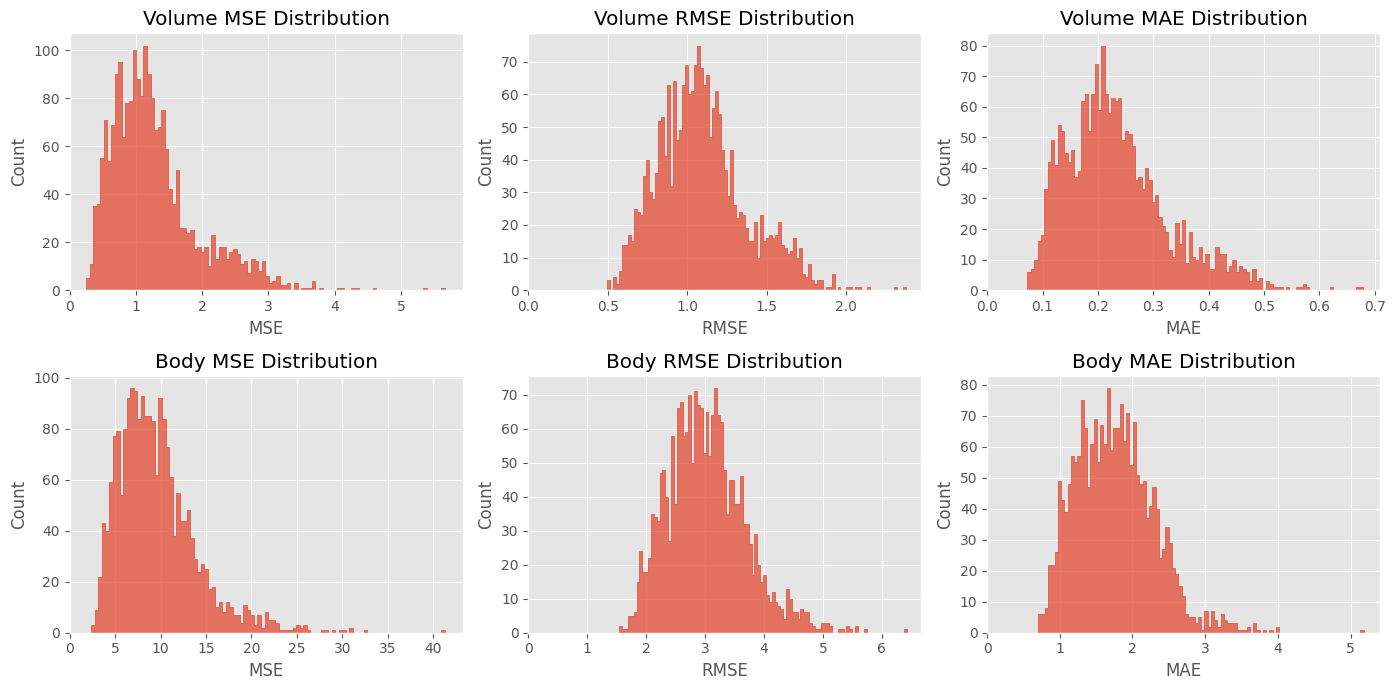

In [151]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7))

for ax, ax_body, metric in zip(axes[0], axes[1], ['mse', 'rmse', 'dose_score']):
  label = 'MAE' if metric == 'dose_score' else metric.upper()
  sns.histplot(all_metrics, x=f'vol_{metric}', element='step', bins=100, ax=ax)
  ax.set_title(f'Volume {label} Distribution')
  ax.set_xlabel(label)
  ax.set_xlim(0)

  sns.histplot(all_metrics, x=f'vol_{metric}_body', element='step', bins=100, ax=ax_body)
  ax_body.set_title(f'Body {label} Distribution')
  ax_body.set_xlabel(label)
  ax_body.set_xlim(0)

fig.tight_layout()

## Spatial-aware Voxel-based Metrics

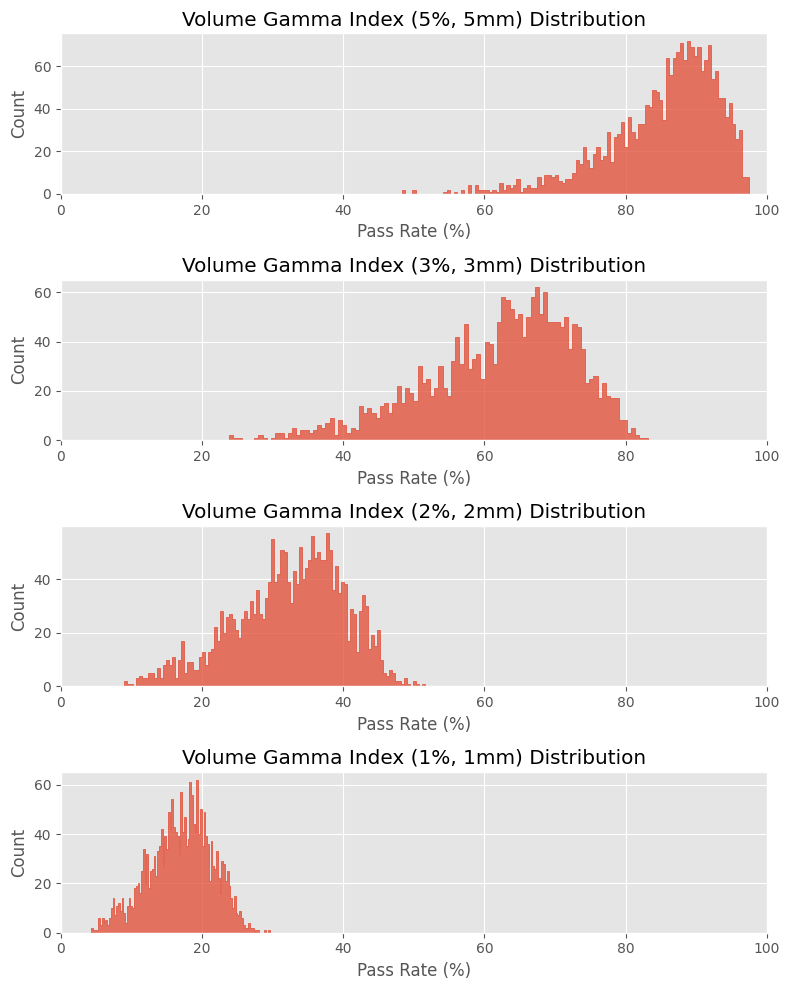

In [97]:
fig, axes = plt.subplots(4, 1, figsize=(8, 10))

for ax, arg in zip(axes, [5, 3, 2, 1]):
  sns.histplot(all_metrics, x=f'vol_gamma_{arg}_{arg}/pass_rate', element='step', bins=100, ax=ax)
  ax.set_title(f'Volume Gamma Index ({arg}%, {arg}mm) Distribution')
  ax.set_xlabel('Pass Rate (%)')
  ax.set_xlim(0, 100)

fig.tight_layout()

## PTV-based Metrics

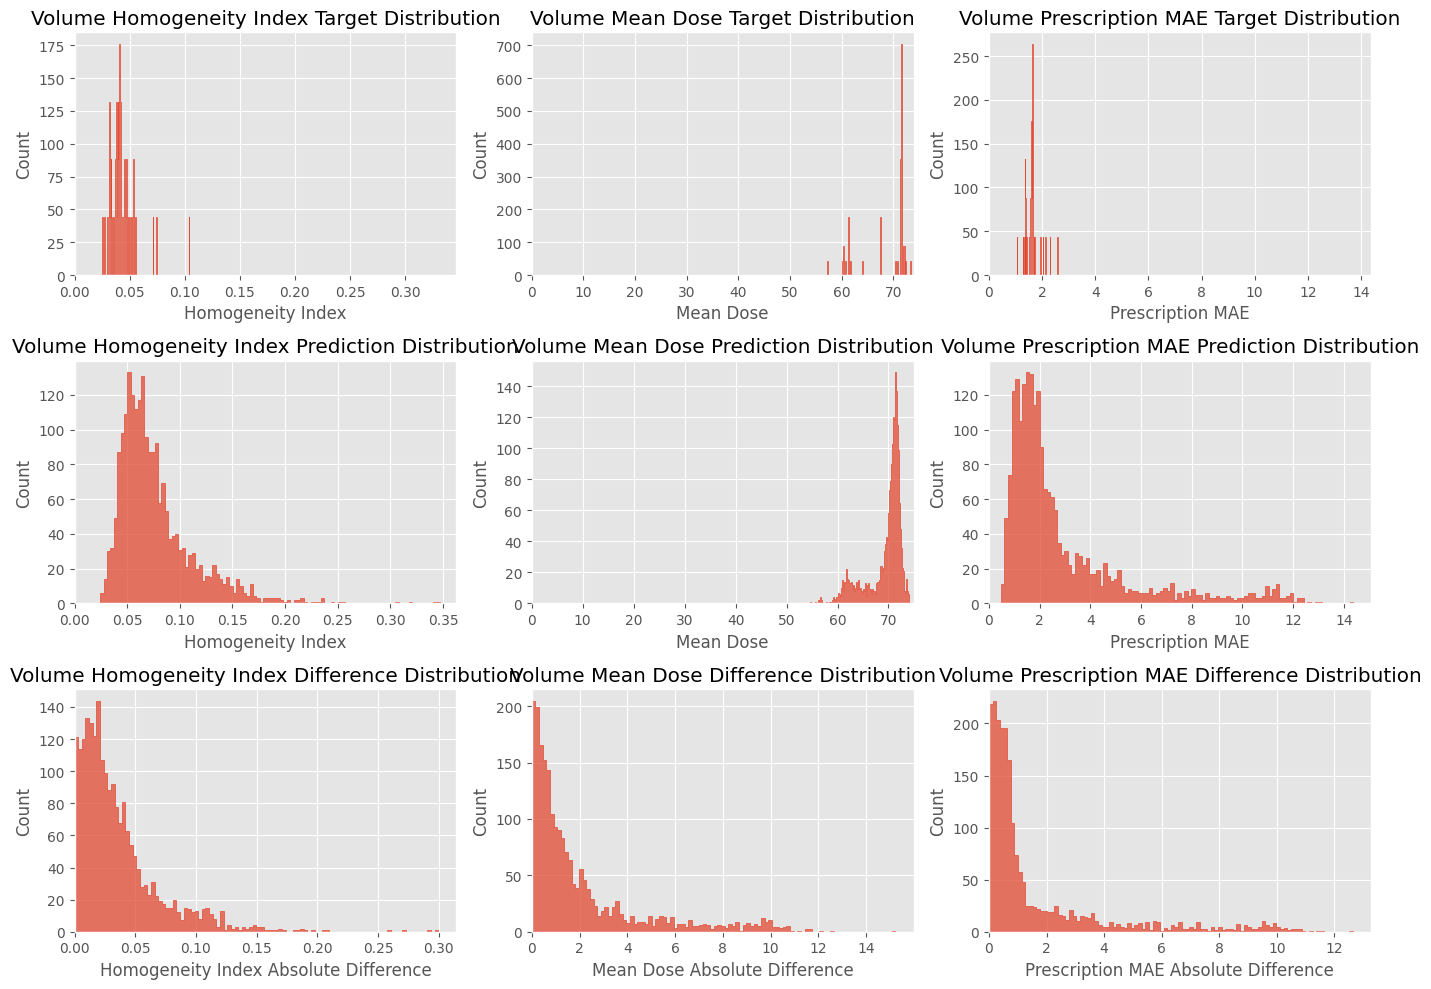

In [98]:
fig, axes = plt.subplots(3, 3, figsize=(14, 10))

for ax_target, ax_pred, ax_diff, metric in zip(axes[0], axes[1], axes[2], ['homogeneity_index', 'mean_dose', 'prescription_mae']):
  label = metric.replace('_', ' ').title().replace('Mae', 'MAE')

  sns.histplot(all_metrics, x=f'vol_{metric}/high/target', element='step', bins=100, ax=ax_target)
  ax_target.set_title(f'Volume {label} Target Distribution')
  ax_target.set_xlabel(label)
  ax_target.set_xlim(0, all_metrics[f'vol_{metric}/high/pred'].max())

  sns.histplot(all_metrics, x=f'vol_{metric}/high/pred', element='step', bins=100, ax=ax_pred)
  ax_pred.set_title(f'Volume {label} Prediction Distribution')
  ax_pred.set_xlabel(label)
  ax_pred.set_xlim(0)

  sns.histplot(all_metrics, x=f'vol_{metric}/high/abs_diff', element='step', bins=100, ax=ax_diff)
  ax_diff.set_title(f'Volume {label} Difference Distribution')
  ax_diff.set_xlabel(f'{label} Absolute Difference')
  ax_diff.set_xlim(0)

fig.tight_layout()

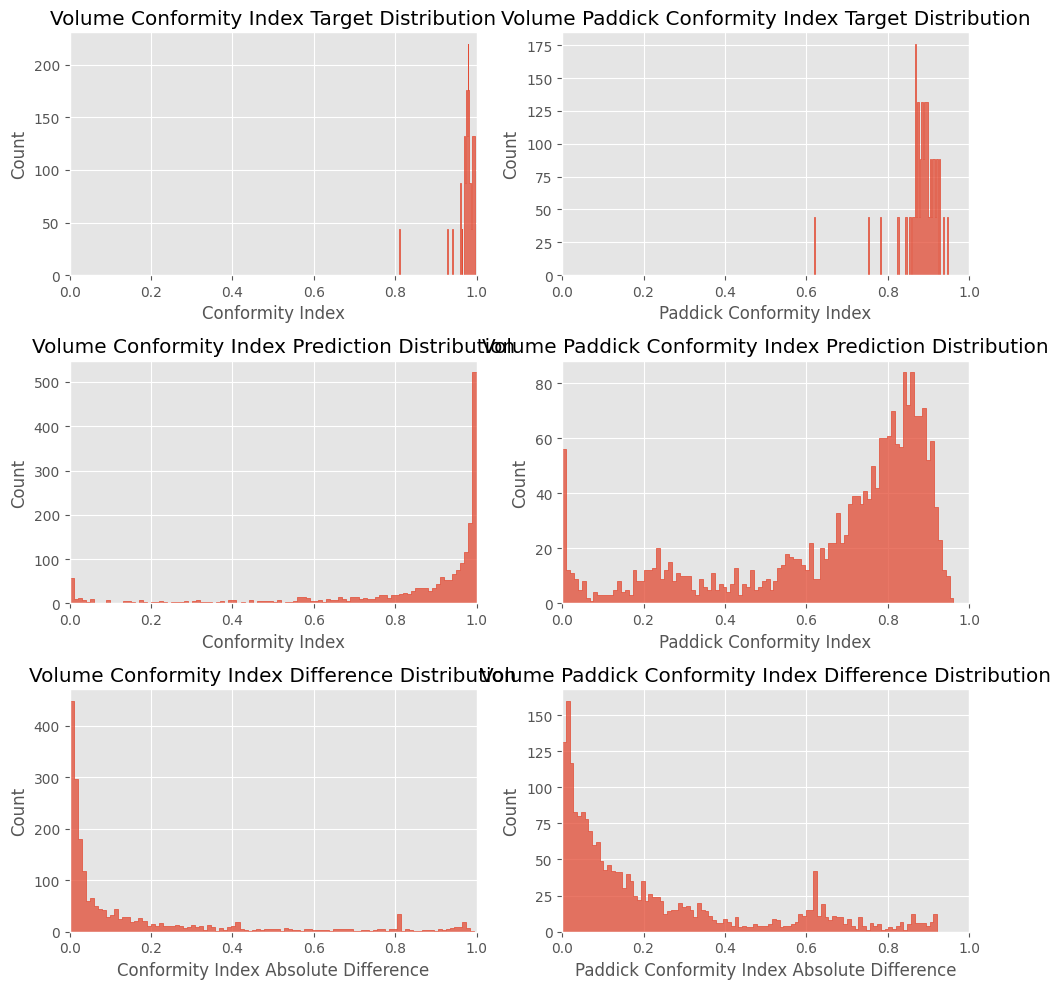

In [99]:
fig, axes = plt.subplots(3, 2, figsize=(10, 10))

for ax_target, ax_pred, ax_diff, metric in zip(axes[0], axes[1], axes[2], ['conformity_index', 'paddick_conformity_index']):
  label = metric.replace('_', ' ').title()

  sns.histplot(all_metrics, x=f'vol_{metric}/high/target', element='step', bins=100, ax=ax_target)
  ax_target.set_title(f'Volume {label} Target Distribution')
  ax_target.set_xlabel(label)
  ax_target.set_xlim(0, 1)

  sns.histplot(all_metrics, x=f'vol_{metric}/high/pred', element='step', bins=100, ax=ax_pred)
  ax_pred.set_title(f'Volume {label} Prediction Distribution')
  ax_pred.set_xlabel(label)
  ax_pred.set_xlim(0, 1)

  sns.histplot(all_metrics, x=f'vol_{metric}/high/abs_diff', element='step', bins=100, ax=ax_diff)
  ax_diff.set_title(f'Volume {label} Difference Distribution')
  ax_diff.set_xlabel(f'{label} Absolute Difference')
  ax_diff.set_xlim(0, 1)

fig.tight_layout()

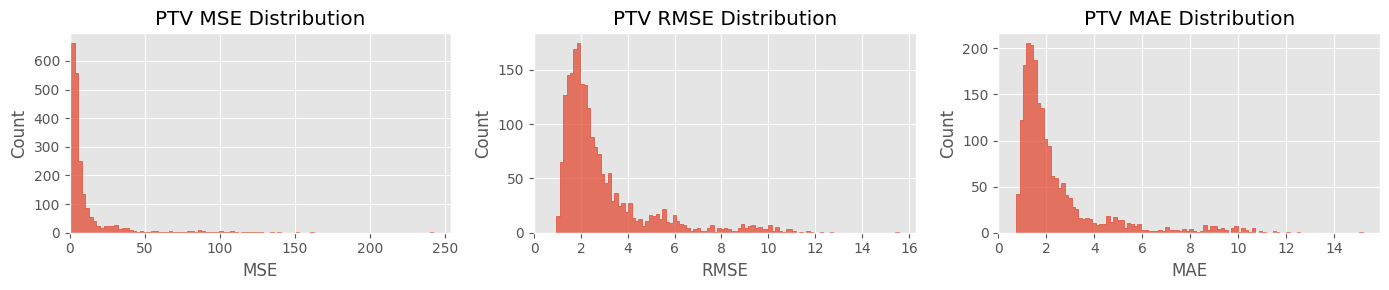

In [100]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3))

for ax, metric in zip(axes, ['mse', 'rmse', 'dose_score']):
  label = 'MAE' if metric == 'dose_score' else metric.upper()
  sns.histplot(all_metrics, x=f'vol_{metric}/PTV', element='step', bins=100, ax=ax)
  ax.set_title(f'PTV {label} Distribution')
  ax.set_xlabel(label)
  ax.set_xlim(0)

fig.tight_layout()

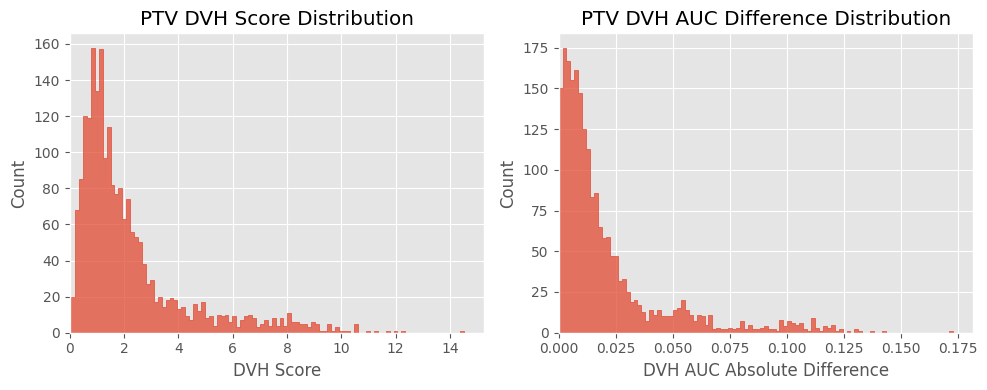

In [101]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

sns.histplot(all_metrics, x=f'vol_dvh/PTV', element='step', bins=100, ax=axes[0])
axes[0].set_title(f'PTV DVH Score Distribution')
axes[0].set_xlabel('DVH Score')
axes[0].set_xlim(0)

sns.histplot(all_metrics, x=f'vol_dvh_auc/PTV/diff', element='step', bins=100, ax=axes[1])
axes[1].set_title(f'PTV DVH AUC Difference Distribution')
axes[1].set_xlabel('DVH AUC Absolute Difference')
axes[1].set_xlim(0)

fig.tight_layout()

## Falloff Metrics

In [102]:
all_metrics['vol_gradient_index/high/pred'].describe()

count     2087.000000
mean       217.090420
std       2899.341673
min          2.535949
25%          5.795154
50%          8.928390
75%         14.747660
max      70524.000000
Name: vol_gradient_index/high/pred, dtype: float64

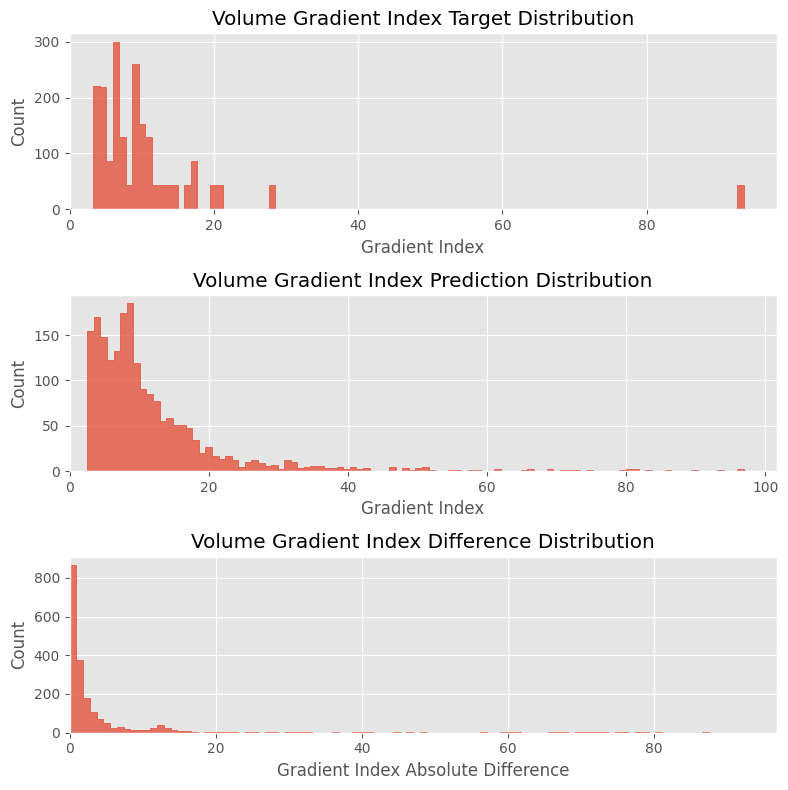

In [103]:
filtered_metrics = all_metrics[all_metrics['vol_gradient_index/high/pred'] < 100]

fig, axes = plt.subplots(3, 1, figsize=(8, 8))

sns.histplot(filtered_metrics, x=f'vol_gradient_index/high/target', element='step', bins=100, ax=axes[0])
axes[0].set_title(f'Volume Gradient Index Target Distribution')
axes[0].set_xlabel('Gradient Index')
axes[0].set_xlim(0)

sns.histplot(filtered_metrics, x=f'vol_gradient_index/high/pred', element='step', bins=100, ax=axes[1])
axes[1].set_title(f'Volume Gradient Index Prediction Distribution')
axes[1].set_xlabel('Gradient Index')
axes[1].set_xlim(0)

sns.histplot(filtered_metrics, x=f'vol_gradient_index/high/abs_diff', element='step', bins=100, ax=axes[2])
axes[2].set_title(f'Volume Gradient Index Difference Distribution')
axes[2].set_xlabel(f'Gradient Index Absolute Difference')
axes[2].set_xlim(0)

fig.tight_layout()

## DVH-based Metrics

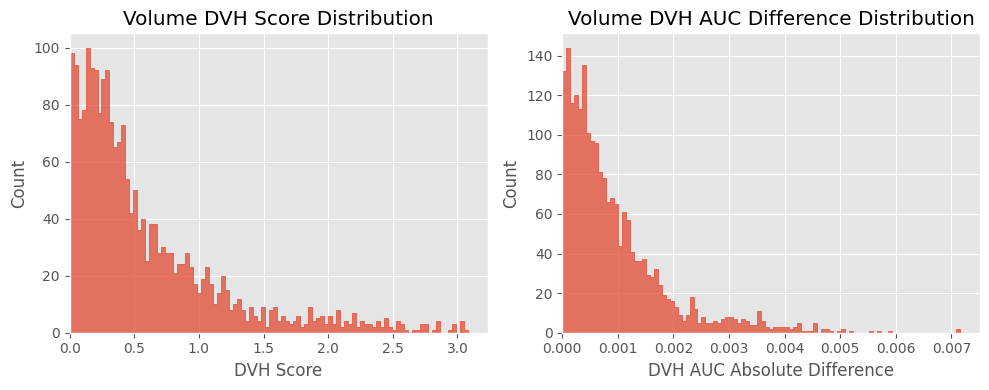

In [104]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

sns.histplot(all_metrics, x=f'vol_dvh', element='step', bins=100, ax=axes[0])
axes[0].set_title(f'Volume DVH Score Distribution')
axes[0].set_xlabel('DVH Score')
axes[0].set_xlim(0)

sns.histplot(all_metrics, x=f'vol_dvh_auc/diff', element='step', bins=100, ax=axes[1])
axes[1].set_title(f'Volume DVH AUC Difference Distribution')
axes[1].set_xlabel('DVH AUC Absolute Difference')
axes[1].set_xlim(0)

fig.tight_layout()

## Constraint-based Metrics

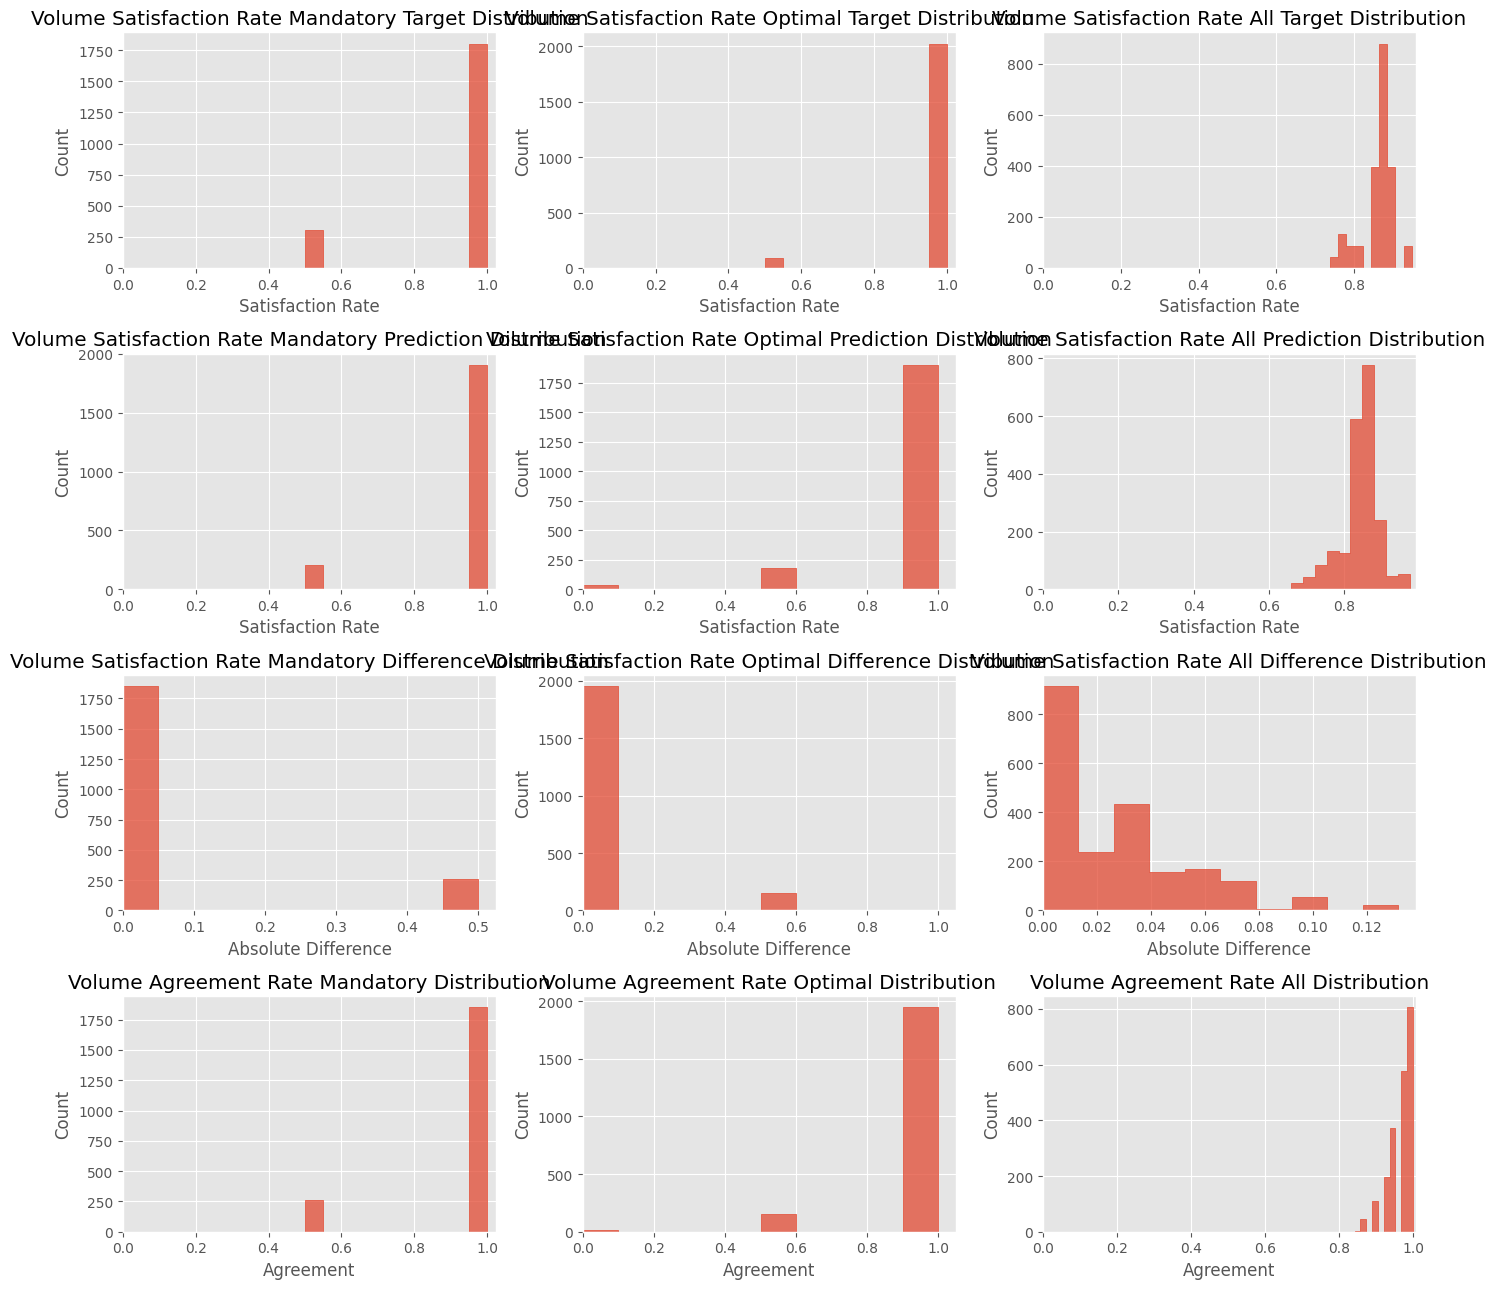

In [105]:
fig, axes = plt.subplots(4, 3, figsize=(14, 13))

for ax_target, ax_pred, ax_diff, ax_agreement, level in zip(axes[0], axes[1], axes[2], axes[3], ['mandatory', 'optimal', 'all']):
  label = level.title()
  sns.histplot(all_metrics, x=f'vol_csr_{level}/csr_target', element='step', bins=10, ax=ax_target)
  ax_target.set_title(f'Volume Satisfaction Rate {label} Target Distribution')
  ax_target.set_xlabel('Satisfaction Rate')
  ax_target.set_xlim(0)

  sns.histplot(all_metrics, x=f'vol_csr_{level}/csr_pred', element='step', bins=10, ax=ax_pred)
  ax_pred.set_title(f'Volume Satisfaction Rate {label} Prediction Distribution')
  ax_pred.set_xlabel('Satisfaction Rate')
  ax_pred.set_xlim(0)

  sns.histplot(all_metrics, x=f'vol_csr_{level}/csr_diff_abs', element='step', bins=10, ax=ax_diff)
  ax_diff.set_title(f'Volume Satisfaction Rate {label} Difference Distribution')
  ax_diff.set_xlabel('Absolute Difference')
  ax_diff.set_xlim(0)

  sns.histplot(all_metrics, x=f'vol_agreement/agreement_{level}', element='step', bins=10, ax=ax_agreement)
  ax_agreement.set_title(f'Volume Agreement Rate {label} Distribution')
  ax_agreement.set_xlabel('Agreement')
  ax_agreement.set_xlim(0)

fig.tight_layout()

## Region-based Metrics

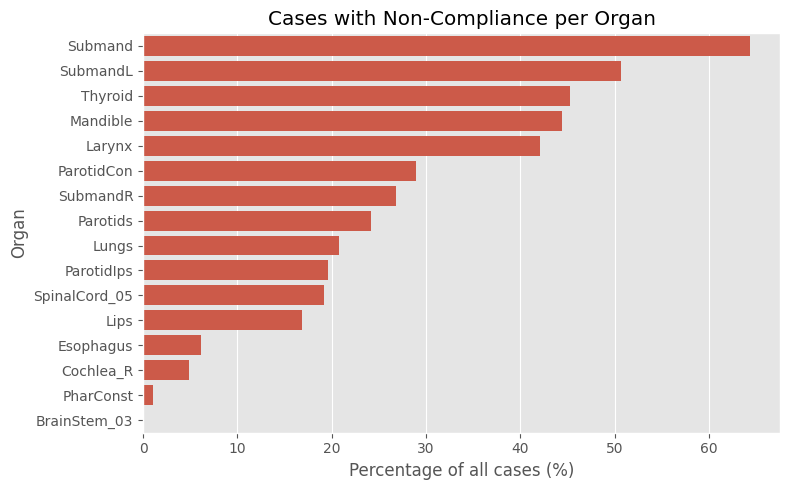

In [106]:
n_per_organ = {}

for organ in GDPHMM_OAR_V3:
  for level in ['mandatory', 'optimal', 'ungraded']:
    key = f'vol_compliance/{organ}/csr_abs_diff_{level}'
    if key in all_metrics and all_metrics[key].std() > 0:
      n_per_organ[organ] = n_per_organ.get(organ, 0) + all_metrics[all_metrics[key] > 0].shape[0]

n_per_organ = pd.Series(n_per_organ).to_frame('n_cases').reset_index(names='organ').sort_values('n_cases', ascending=False)
n_per_organ['organ'] = n_per_organ['organ'].str.replace('-PTV', '', regex=False)
n_per_organ['n_cases'] = n_per_organ['n_cases'] / len(all_metrics) * 100

fig, ax = plt.subplots(1, 1, figsize=(8, 5))
sns.barplot(data=n_per_organ, x='n_cases', y='organ', ax=ax)
ax.set_title('Cases with Non-Compliance per Organ')
ax.set_xlabel('Percentage of all cases (%)')
ax.set_ylabel('Organ')
fig.tight_layout()

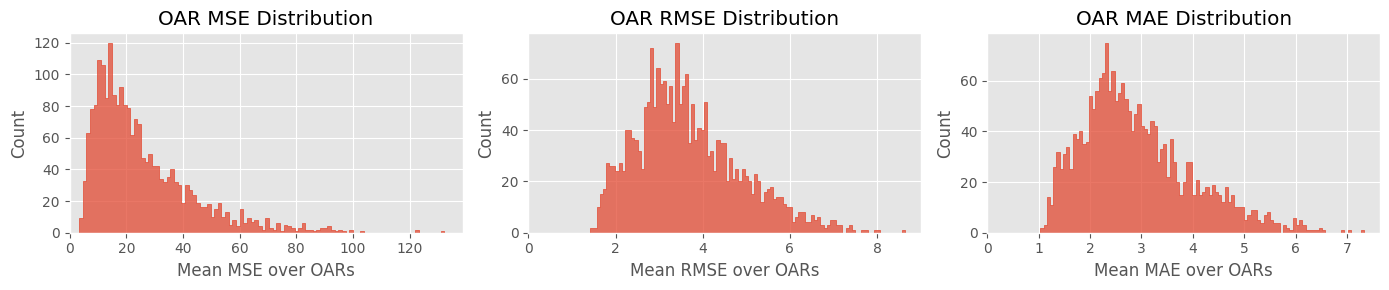

In [108]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3))

for ax, metric in zip(axes, ['mse', 'rmse', 'dose_score']):
  label = 'MAE' if metric == 'dose_score' else metric.upper()
  sns.histplot(all_metrics, x=f'vol_{metric}/OAR', element='step', bins=100, ax=ax)
  ax.set_title(f'OAR {label} Distribution')
  ax.set_xlabel(f'Mean {label} over OARs')
  ax.set_xlim(0)

fig.tight_layout()

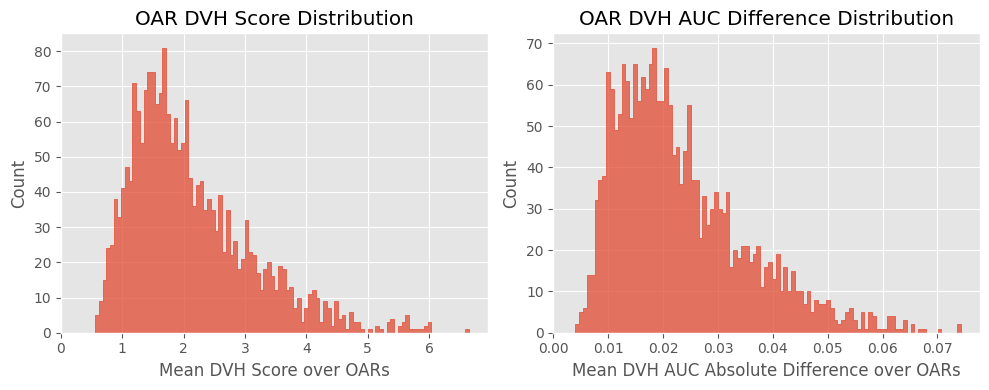

In [155]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

sns.histplot(all_metrics, x=f'vol_dvh/OAR', element='step', bins=100, ax=axes[0])
axes[0].set_title(f'OAR DVH Score Distribution')
axes[0].set_xlabel('Mean DVH Score over OARs')
axes[0].set_xlim(0)

sns.histplot(all_metrics, x=f'vol_dvh_auc/OAR/diff', element='step', bins=100, ax=axes[1])
axes[1].set_title(f'OAR DVH AUC Difference Distribution')
axes[1].set_xlabel('Mean DVH AUC Absolute Difference over OARs')
axes[1].set_xlim(0)

fig.tight_layout()

# Correlations

In [152]:
metrics = [
  'vol_mse',
  'vol_rmse',
  'vol_dose_score',
  'vol_mse_body',
  'vol_rmse_body',
  'vol_dose_score_body',
  'vol_gamma_5_5/pass_rate',
  'vol_gamma_3_3/pass_rate',
  'vol_gamma_2_2/pass_rate',
  'vol_gamma_1_1/pass_rate',
  'vol_homogeneity_index/high/abs_diff',
  'vol_mean_dose/high/abs_diff',
  'vol_prescription_mae/high/abs_diff',
  'vol_conformity_index/high/abs_diff',
  'vol_paddick_conformity_index/high/abs_diff',
  'vol_mse/PTV',
  'vol_rmse/PTV',
  'vol_dose_score/PTV',
  'vol_dvh/PTV',
  'vol_dvh_auc/PTV/diff',
  'vol_gradient_index/high/abs_diff',
  'vol_dvh',
  'vol_dvh_auc/diff',
  'vol_csr_all/csr_diff_abs',
  'vol_agreement/agreement_all',
  'vol_mse/OAR',
  'vol_rmse/OAR',
  'vol_dose_score/OAR',
  'vol_dvh/OAR',
  'vol_dvh_auc/OAR/diff',
]

p_corr_mat = all_metrics[metrics].corr(method='pearson')
sp_corr_mat = all_metrics[metrics].corr(method='spearman')

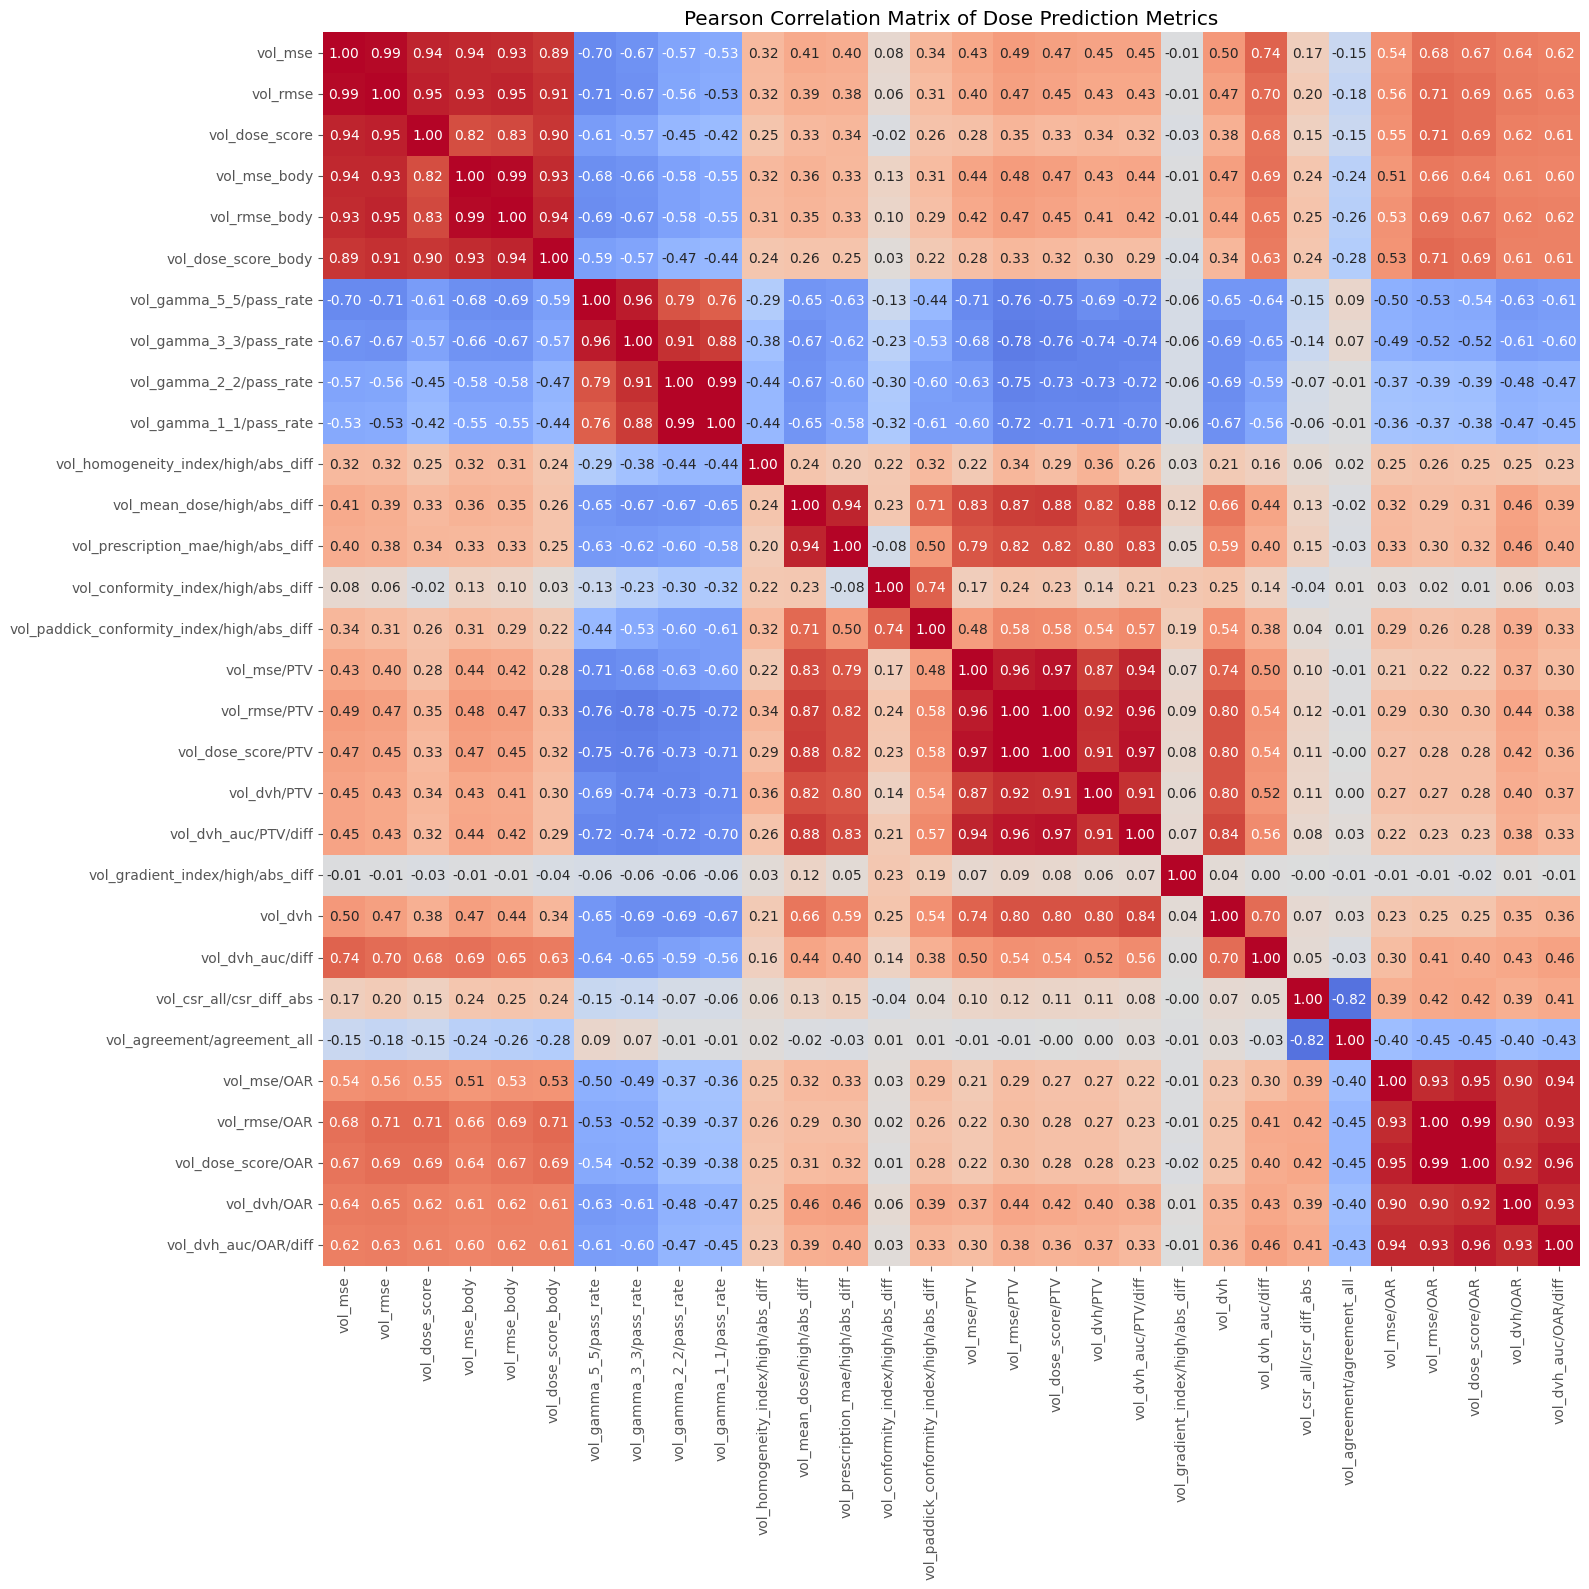

In [153]:
fig, ax = plt.subplots(1, 1, figsize=(16, 16))
sns.heatmap(p_corr_mat, annot=True, fmt='.2f', cmap='coolwarm', vmax=1, vmin=-1, cbar=False, ax=ax)
ax.set_title('Pearson Correlation Matrix of Dose Prediction Metrics')
fig.tight_layout()

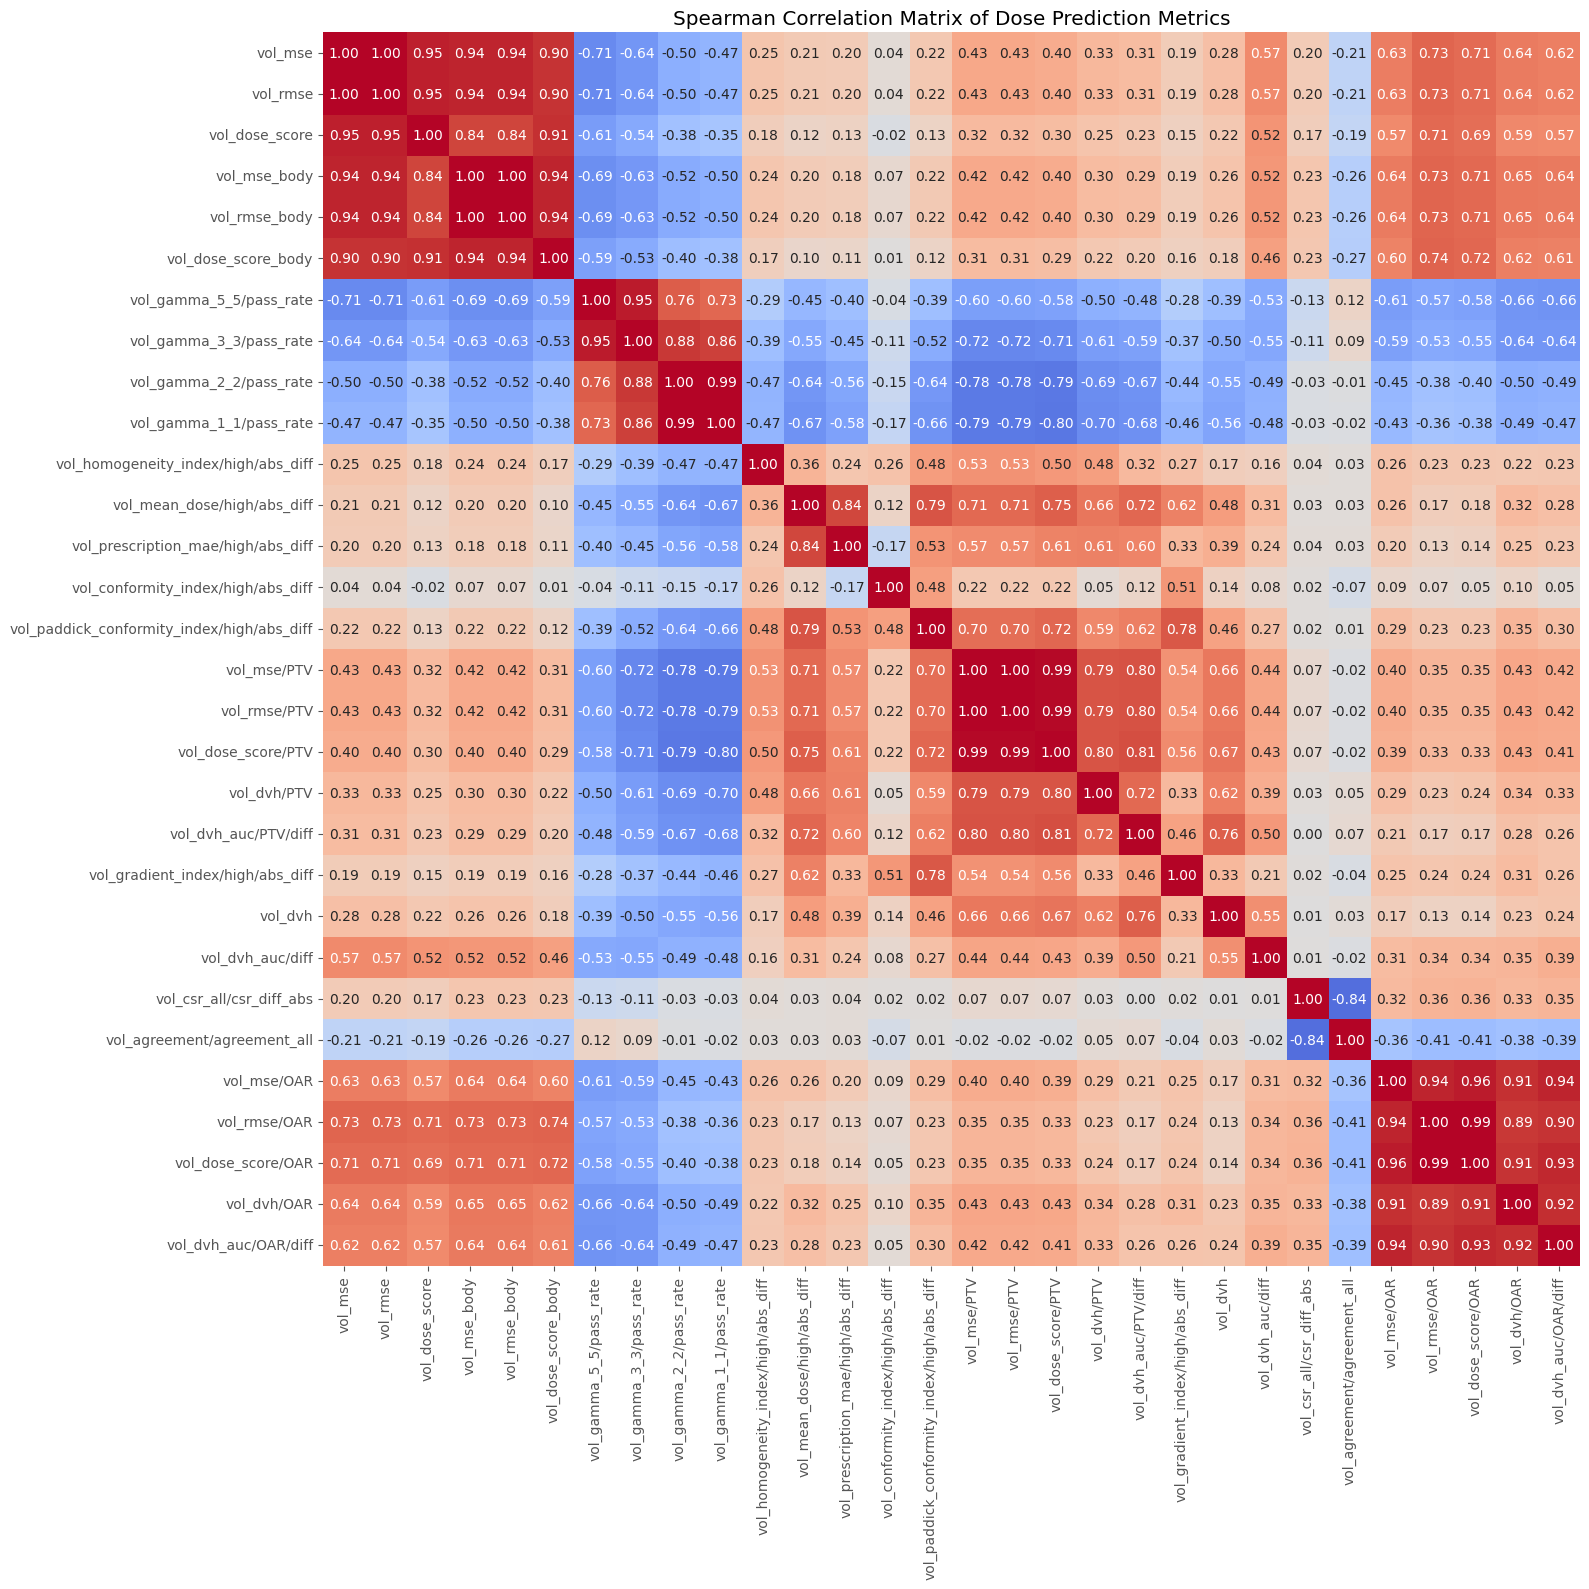

In [154]:
fig, ax = plt.subplots(1, 1, figsize=(16, 16))
sns.heatmap(sp_corr_mat, annot=True, fmt='.2f', cmap='coolwarm', vmax=1, vmin=-1, cbar=False, ax=ax)
ax.set_title('Spearman Correlation Matrix of Dose Prediction Metrics')
fig.tight_layout()

# Selected Metrics

In General: all metrics relative to ground truth which is assumed to be perfect, but probably isn't.

- **vol/rmse_body**: for exact voxel accuracy, better interpretability than MSE and non-body metrics, more sensitive to huge errors than MAE
- **vol_gamma_3_3/pass_rate**: for some spatial awareness, widely used in clinic, easy to interpret, less sensitive to small errors than voxel-based metrics, optimized implemntation, widely accepted thresholds (incl. 10% LDT, global calculation (relative to highest dose in GT)), 1mm and 2mm do not make sense with CT resolution (2, 2, 2.5mm)
- **vol_agreement/agreement_all**: comparison on constraint level, easy to interpret, helps checking for larger issues in DVH, less sensitive to small errors than voxel-based metrics
- **vol_dvh**: widely used in literature, helps checking for larger issues in DVH, but only used for comparison with literature
- **vol_dvh_auc/OAR/diff**: metric for DVH curves, checks if the radiation dose to OARs aligns with GT

PTV-based metrics: Standalone and comparison with target (combined plot?):

- **vol_mean_dose**: check correct value
- **vol_homogeneity_index**: check variance
- **vol_paddick_conformity_index**: check spatial correctness, widely used in clinic, easy to interpret
- **vol_gradient_index**: check falloff

Other considerations:

- no PTV-specific and OAR-specificerror metrics (RMSE, ...) because its validated with voxel-based metrics already and relevant concepts are validated with domain-specific metrics

# Visualizations

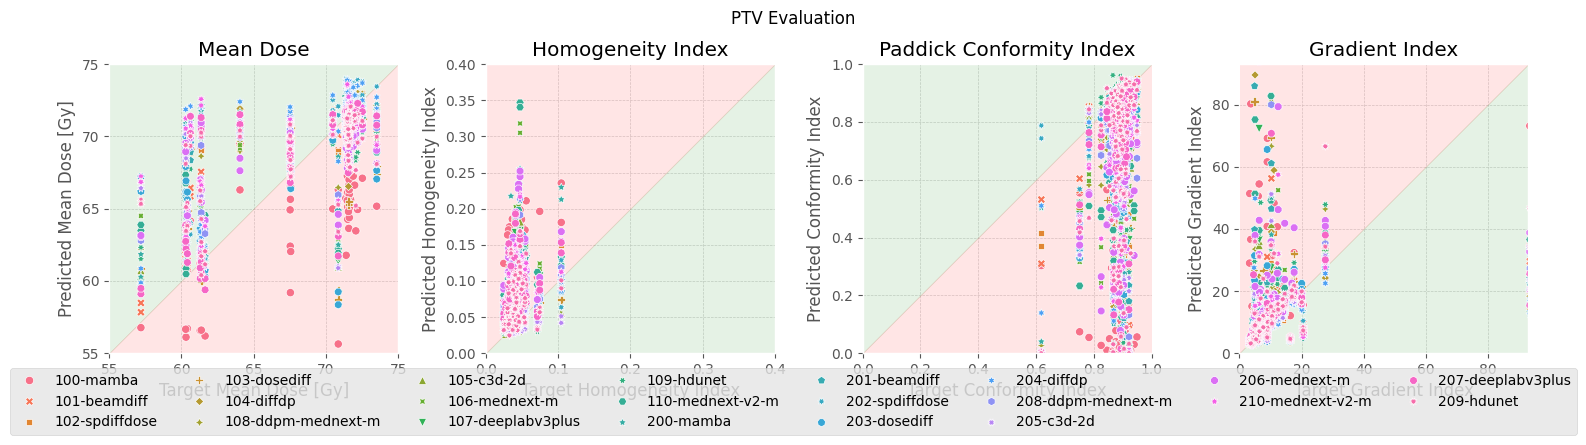

In [159]:
filtered_metrics = all_metrics#[all_metrics['model_name']].isin([
#     '100-mamba',
#     '101-beamdiff',
#     '102-spdiffdose',
# ])]

fig, axes = plt.subplots(1, 4, figsize=(15, 4))

axes[0].fill_between([55, 75], [55, 75], 75, color='green', alpha=0.1)
axes[0].fill_between([55, 75], [55, 75], 55, color='red', alpha=0.1)
sns.scatterplot(filtered_metrics, x=f'vol_mean_dose/high/target', y=f'vol_mean_dose/high/pred', style='model_name', hue='model_name', ax=axes[0], legend='full')
#axes[0].set_title(r'Mean Dose $\tilde{x} = ' + str(filtered_metrics['vol_mean_dose/high/abs_diff'].median().round(2)) + '$')
axes[0].set_title('Mean Dose')
axes[0].set_xlabel('Target Mean Dose [Gy]')
axes[0].set_ylabel('Predicted Mean Dose [Gy]')
axes[0].set_xlim(55, 75)
axes[0].set_ylim(55, 75)
axes[0].xaxis.get_major_locator().set_params(integer=True)
axes[0].yaxis.get_major_locator().set_params(integer=True)

axes[1].fill_between([0, 0.4], [0, 0.4], 0.4, color='red', alpha=0.1)
axes[1].fill_between([0, 0.4], [0, 0.4], 0, color='green', alpha=0.1)
sns.scatterplot(filtered_metrics, x=f'vol_homogeneity_index/high/target', y=f'vol_homogeneity_index/high/pred', style='model_name', hue='model_name', ax=axes[1])
axes[1].set_title(f'Homogeneity Index')
axes[1].set_xlabel('Target Homogeneity Index')
axes[1].set_ylabel('Predicted Homogeneity Index')
axes[1].set_xlim(0, 0.40)
axes[1].set_ylim(0, 0.40)

axes[2].fill_between([0, 1], [0, 1], 1, color='green', alpha=0.1)
axes[2].fill_between([0, 1], [0, 1], 0, color='red', alpha=0.1)
sns.scatterplot(filtered_metrics, x=f'vol_paddick_conformity_index/high/target', y=f'vol_paddick_conformity_index/high/pred', style='model_name', hue='model_name', ax=axes[2])
axes[2].set_title(f'Paddick Conformity Index')
axes[2].set_xlabel('Target Conformity Index')
axes[2].set_ylabel('Predicted Conformity Index')
axes[2].set_xlim(0, 1.0)
axes[2].set_ylim(0, 1.0)

axes[3].fill_between([0, 93], [0, 93], 93, color='red', alpha=0.1)
axes[3].fill_between([0, 93], [0, 93], 0, color='green', alpha=0.1)
sns.scatterplot(filtered_metrics, x=f'vol_gradient_index/high/target', y=f'vol_gradient_index/high/pred', style='model_name', hue='model_name', ax=axes[3])
axes[3].set_title(f'Gradient Index')
axes[3].set_xlabel('Target Gradient Index')
axes[3].set_ylabel('Predicted Gradient Index')
axes[3].set_xlim(0, 93)
axes[3].set_ylim(0, 93)

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', title='', ncol=8, bbox_to_anchor=(0.5, -0.1))

for ax in axes:
  ax.grid(True, color='lightgray', linestyle='--', linewidth=0.5)
  ax.set_aspect('equal')
  ax.get_legend().remove()
  ax.set_facecolor('white')

fig.suptitle('PTV Evaluation')
fig.tight_layout()